# Colas de prioridad y árbol de expansión mínima
**Diseño y Desarrollo de Algoritmos — 2026-2**

## 1) Descripción del problema
Una empresa necesita organizar sus tareas técnicas según su prioridad y conectar seis dispositivos utilizando la menor cantidad posible de cable. Para ello se implementa una cola de prioridad mediante un Max-Heap, que permite procesar primero las tareas más urgentes. Además, se aplica el algoritmo de Kruskal para obtener un árbol de expansión mínima (MST), evitando ciclos y minimizando la suma de las distancias de las conexiones.

## 2) Requerimientos
**Funcionales**
- RF01. Registrar las seis tareas con código, descripción y prioridad; mostrar el arreglo inicial.
- RF02. Construir el Max-Heap mediante MAX-HEAPIFY y BUILD-MAX-HEAP y mostrar el arreglo y el árbol resultantes.
- RF03. Extraer las dos tareas de mayor prioridad con EXTRACT-MAX y mostrar el heap después de cada extracción.
- RF04. Insertar T07 con prioridad 12, conservar la propiedad del Max-Heap y mostrar el resultado.
- RF05. Graficar los seis dispositivos y calcular automáticamente todas las distancias euclidianas entre parejas.
- RF06. Ordenar las aristas por peso y aplicar Kruskal manualmente, evitando ciclos y deteniéndose al obtener cinco conexiones.
- RF07. Mostrar las aristas seleccionadas, sus pesos, la longitud total de cable y la gráfica final del MST.

**No funcionales y restricciones**
- RNF01. Desarrollar la solución en Python en un único Notebook ejecutable.
- RNF02. No utilizar `heapq` ni funciones de librerías que calculen directamente el MST.
- RNF03. Presentar resultados claros y reproducibles; conservar la precisión de las distancias hasta su presentación.
- RNF04. Utilizar estructuras de datos apropiadas y verificar los resultados mediante pruebas.
- RNF05. Guardar el archivo como `parcial_prioridad_mst.ipynb`. La entrega en GitHub debe utilizar la rama `parcial-prioridad-mst`, un Pull Request hacia `main` con descripción y evidencias, y su posterior merge.

## 3) Historias de usuario
1. **HU01. Organización de tareas.** Como administrador, quiero organizar las tareas por prioridad para identificar las más urgentes.
   - Criterio de aceptación: el Max-Heap contiene las seis tareas y T02 queda en la raíz con prioridad 10.
2. **HU02. Procesamiento.** Como técnico, quiero extraer las tareas más urgentes para atenderlas primero.
   - Criterio de aceptación: se extraen T02 y T04 en ese orden, manteniendo la propiedad del heap después de cada operación.
3. **HU03. Inserción.** Como administrador, quiero agregar una tarea urgente para actualizar la cola.
   - Criterio de aceptación: T07 queda en la raíz con prioridad 12 y las demás tareas pendientes se conservan.
4. **HU04. Distancias.** Como ingeniero, quiero calcular las distancias entre los dispositivos para conocer los costos de conexión.
   - Criterio de aceptación: se representan los seis dispositivos y se calculan 15 distancias euclidianas sin duplicar parejas.
5. **HU05. Optimización de conexiones.** Como ingeniero, quiero conectar todos los dispositivos utilizando la menor cantidad de cable para reducir costos.
   - Criterio de aceptación: se obtienen cinco conexiones, sin ciclos, con longitud total de 25,50 unidades aproximadamente y una gráfica con los pesos.

## 4) Diagrama de flujo
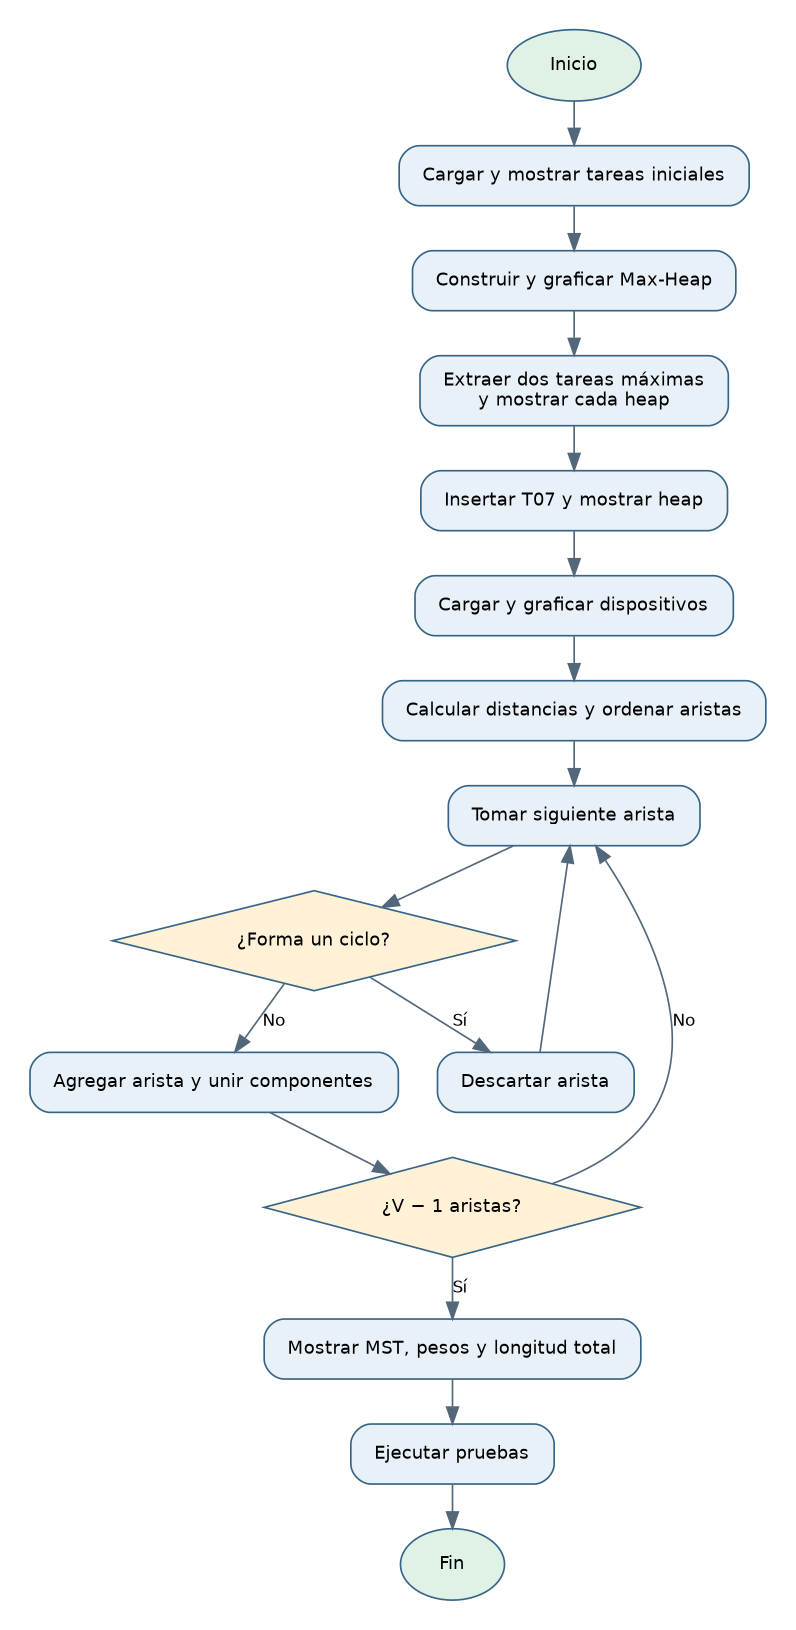

El proceso comienza con la carga de las tareas y la construcción del Max-Heap. Se extraen las dos tareas de mayor prioridad y se inserta T07. Luego se representan los dispositivos, se calculan y ordenan sus distancias, y Kruskal examina las aristas de menor a mayor peso. Las que generan ciclos se descartan y las demás se agregan al MST hasta completar cinco conexiones. Finalmente, se muestran las gráficas y se ejecutan los tests. El grafo del problema es completo, por lo que siempre existe una conexión entre las componentes restantes.

## 5) Análisis de complejidad
### Justificación
Se usa $n$ para el número de tareas, $V$ para el número de dispositivos y $E$ para el número de aristas. El Max-Heap es un árbol binario completo de altura $\lfloor\log_2 n\rfloor$. MAX-HEAPIFY puede descender hasta una hoja; la inserción puede ascender hasta la raíz. BUILD-MAX-HEAP es lineal porque la mayoría de los nodos están cerca de las hojas: la suma de las alturas de todos los nodos es $O(n)$.

Para los dispositivos se generan $E=V(V-1)/2$ aristas. Kruskal ordena esas aristas y utiliza conjuntos disjuntos con compresión de caminos y unión por rango. El ordenamiento domina en el peor caso; la gestión de conjuntos tiene costo amortizado $O(E\alpha(V))$, donde $\alpha$ es la inversa de Ackermann. El mejor caso con `sorted` de Python, cuando las aristas ya están ordenadas y se aceptan las primeras necesarias, es lineal en $E$.

| Operación | Mejor caso | Peor caso |
|---|---|---|
| MAX-HEAPIFY | $\Theta(1)$ | $O(\log n)$ |
| BUILD-MAX-HEAP | $\Theta(n)$ | $\Theta(n)$ |
| EXTRACT-MAX | $\Theta(1)$ | $O(\log n)$ |
| Inserción (costo amortizado) | $\Theta(1)$ | $O(\log n)$ |
| Cálculo de distancias | $\Theta(V^2)$ | $\Theta(V^2)$ |
| Kruskal (grafo completo) | $\Theta(E)$ | $O(E\log E)$ |

### Función T[n] y justificación
Para la secuencia de una construcción, dos extracciones y una inserción, se propone un modelo de crecimiento con constantes unitarias:

$$T_{mejor}(n)=n+3$$
$$T_{peor}(n)=n+3\lceil\log_2(n)\rceil$$

Ambos modelos crecen linealmente: $\Theta(n)$. La visualización y la impresión de los arreglos agregan trabajo lineal para esta cantidad fija de operaciones. Las expresiones son modelos teóricos, no conteos exactos de instrucciones ni tiempos medidos.

Para la fase de conexión, incluyendo generación de aristas y ordenamiento, se emplean los modelos:

$$E=\frac{V(V-1)}{2}$$
$$T_{mejor}(V)=2E,\qquad T_{peor}(V)=2E+E\log_2(E)$$

Para seis dispositivos, $E=15$. El mejor caso es $\Theta(V^2)$ y el peor caso queda acotado por $O(V^2\log V)$. El espacio auxiliar de las etapas de conexión es $O(V+E)=O(V^2)$, y el almacenamiento de la cola es $O(n)$.

### Mejor y peor caso
En el mejor caso, las operaciones individuales del heap no necesitan intercambios y las aristas ya están ordenadas, permitiendo seleccionar las conexiones sin muchos descartes. En el peor caso, las operaciones individuales recorren la altura del heap, las aristas requieren ordenamiento completo y se revisan conexiones que pueden generar ciclos. Las gráficas siguientes muestran los modelos teóricos para ambas etapas.

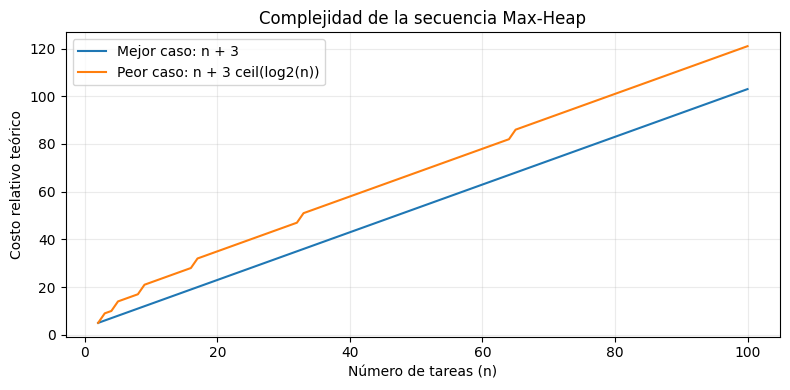

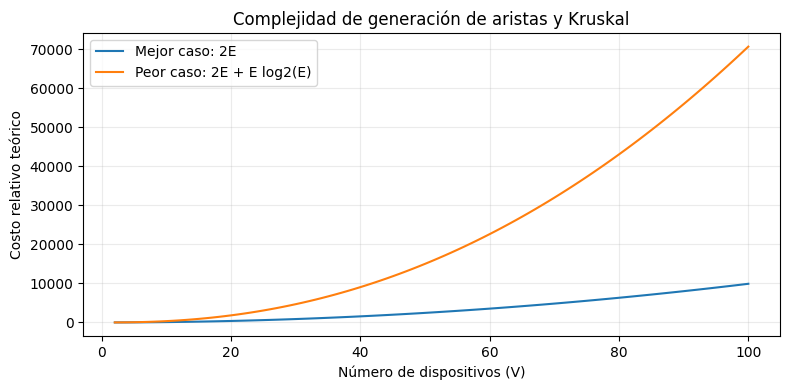

In [1]:
import math
import matplotlib.pyplot as plt

n = list(range(2, 101))
mejor_heap = [k + 3 for k in n]
peor_heap = [k + 3 * math.ceil(math.log2(k)) for k in n]

plt.figure(figsize=(8, 4))
plt.plot(n, mejor_heap, label="Mejor caso: n + 3")
plt.plot(n, peor_heap, label="Peor caso: n + 3 ceil(log2(n))")
plt.xlabel("Número de tareas (n)")
plt.ylabel("Costo relativo teórico")
plt.title("Complejidad de la secuencia Max-Heap")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

v = list(range(2, 101))
e = [k * (k-1) // 2 for k in v]
mejor_mst = [2*m for m in e]
peor_mst = [2*m + m*math.log2(m) for m in e]

plt.figure(figsize=(8, 4))
plt.plot(v, mejor_mst, label="Mejor caso: 2E")
plt.plot(v, peor_mst, label="Peor caso: 2E + E log2(E)")
plt.xlabel("Número de dispositivos (V)")
plt.ylabel("Costo relativo teórico")
plt.title("Complejidad de generación de aristas y Kruskal")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

## 6) Código funcional
La implementación completa está organizada en los cinco puntos del enunciado. Ejecutar las celdas en orden. Se usan únicamente Python, `math` para las distancias y `matplotlib` para las visualizaciones; las operaciones del heap y el algoritmo de Kruskal se implementan manualmente.

### Punto 1. Cola de prioridad
Cada tarea se representa mediante una tupla `(código, tarea, prioridad)`. La raíz del Max-Heap contiene la tarea de mayor prioridad. Se construye el heap de abajo hacia arriba, aplicando MAX-HEAPIFY a los nodos internos.

In [2]:
import math
import matplotlib.pyplot as plt

heap = [
    ("T01", "Configurar servidor", 6),
    ("T02", "Reparar sensor", 10),
    ("T03", "Actualizar software", 4),
    ("T04", "Revisar cámara", 8),
    ("T05", "Generar respaldo", 3),
    ("T06", "Configurar alarma", 7)
]

def mostrar_heap(h):
    print([(t[0], t[2]) for t in h])

def max_heapify(h, i):
    n = len(h)
    while True:
        mayor = i
        izq = 2*i + 1
        der = 2*i + 2
        if izq < n and h[izq][2] > h[mayor][2]:
            mayor = izq
        if der < n and h[der][2] > h[mayor][2]:
            mayor = der
        if mayor == i:
            break
        h[i], h[mayor] = h[mayor], h[i]
        i = mayor

def build_max_heap(h):
    for i in range(len(h)//2 - 1, -1, -1):
        max_heapify(h, i)

def es_max_heap(h):
    return all(h[(i-1)//2][2] >= h[i][2] for i in range(1, len(h)))

print("Arreglo inicial:")
mostrar_heap(heap)
build_max_heap(heap)
print("Max-Heap resultante:")
mostrar_heap(heap)
assert es_max_heap(heap)

Arreglo inicial:
[('T01', 6), ('T02', 10), ('T03', 4), ('T04', 8), ('T05', 3), ('T06', 7)]
Max-Heap resultante:
[('T02', 10), ('T04', 8), ('T06', 7), ('T01', 6), ('T05', 3), ('T03', 4)]


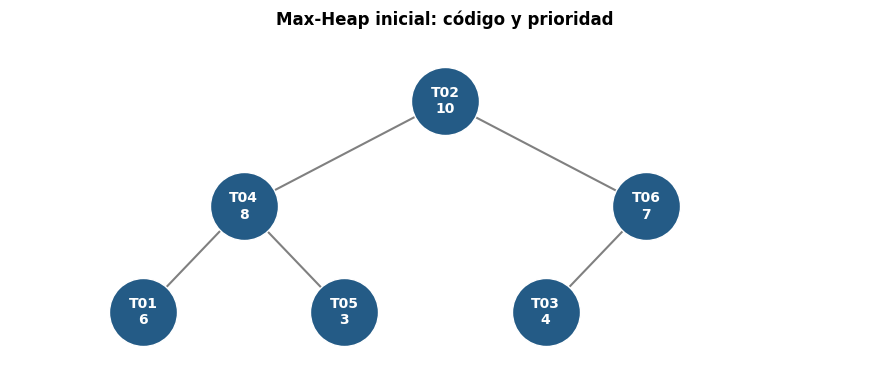

In [3]:
def dibujar_heap(h, titulo):
    fig, ax = plt.subplots(figsize=(9, 4))
    posiciones = {}
    for i in range(len(h)):
        nivel = (i+1).bit_length()-1
        lugar = i-(2**nivel-1)
        posiciones[i] = ((lugar+0.5)/2**nivel, -nivel)
    for i in range(1, len(h)):
        x1, y1 = posiciones[(i-1)//2]
        x2, y2 = posiciones[i]
        ax.plot([x1,x2], [y1,y2], color="gray", zorder=1)
    for i, tarea in enumerate(h):
        x,y = posiciones[i]
        ax.scatter(x,y,s=2400,color="#245b86",edgecolors="white",zorder=2)
        ax.text(x,y,f"{tarea[0]}\n{tarea[2]}",ha="center",va="center",color="white",weight="bold",zorder=3)
    ax.set_xlim(-0.04,1.04)
    ax.set_ylim(min(y for x,y in posiciones.values())-0.65,0.65)
    ax.set_title(titulo,weight="bold")
    ax.axis("off")
    fig.tight_layout()
    return fig

fig = dibujar_heap(heap, "Max-Heap inicial: código y prioridad")
plt.show()

### Punto 2. Procesar tareas
EXTRACT-MAX retira la raíz, mueve el último elemento a la raíz y restablece el heap. Para insertar una tarea, se agrega al final y se intercambia con su padre mientras tenga mayor prioridad.

Tarea procesada: T02 - Reparar sensor - Prioridad 10
Heap resultante:
[('T04', 8), ('T01', 6), ('T06', 7), ('T03', 4), ('T05', 3)]

Tarea procesada: T04 - Revisar cámara - Prioridad 8
Heap resultante:
[('T06', 7), ('T01', 6), ('T05', 3), ('T03', 4)]

Heap después de insertar T07:
[('T07', 12), ('T06', 7), ('T05', 3), ('T03', 4), ('T01', 6)]


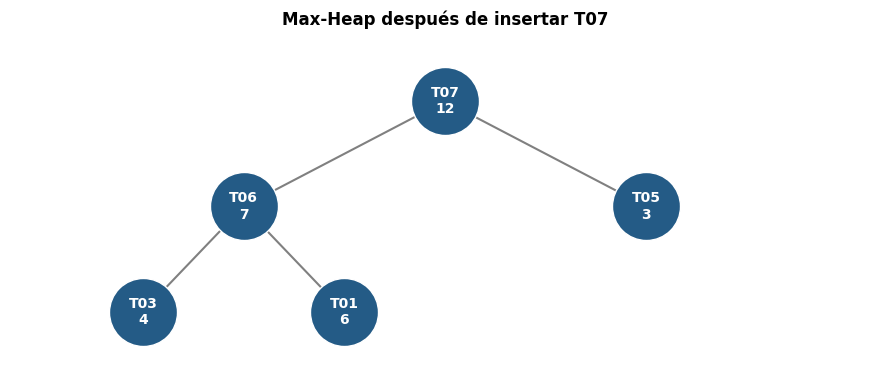

In [4]:
def extract_max(h):
    if not h:
        raise IndexError("La cola está vacía")
    maxima = h[0]
    ultimo = h.pop()
    if h:
        h[0] = ultimo
        max_heapify(h, 0)
    return maxima

def insertar(h, tarea):
    h.append(tarea)
    i = len(h)-1
    while i > 0:
        padre = (i-1)//2
        if h[padre][2] >= h[i][2]:
            break
        h[i], h[padre] = h[padre], h[i]
        i = padre

for _ in range(2):
    tarea = extract_max(heap)
    print(f"Tarea procesada: {tarea[0]} - {tarea[1]} - Prioridad {tarea[2]}")
    print("Heap resultante:")
    mostrar_heap(heap)
    assert es_max_heap(heap)
    print()

nueva = ("T07", "Falla en sistema contra incendios", 12)
insertar(heap, nueva)
print("Heap después de insertar T07:")
mostrar_heap(heap)
assert es_max_heap(heap)
fig = dibujar_heap(heap, "Max-Heap después de insertar T07")
plt.show()

### Punto 3. Dispositivos a conectar
Se representan los seis dispositivos en el plano cartesiano y se calcula la distancia euclidiana de cada pareja. Cada arista se genera una sola vez, para un total de 15 conexiones posibles.

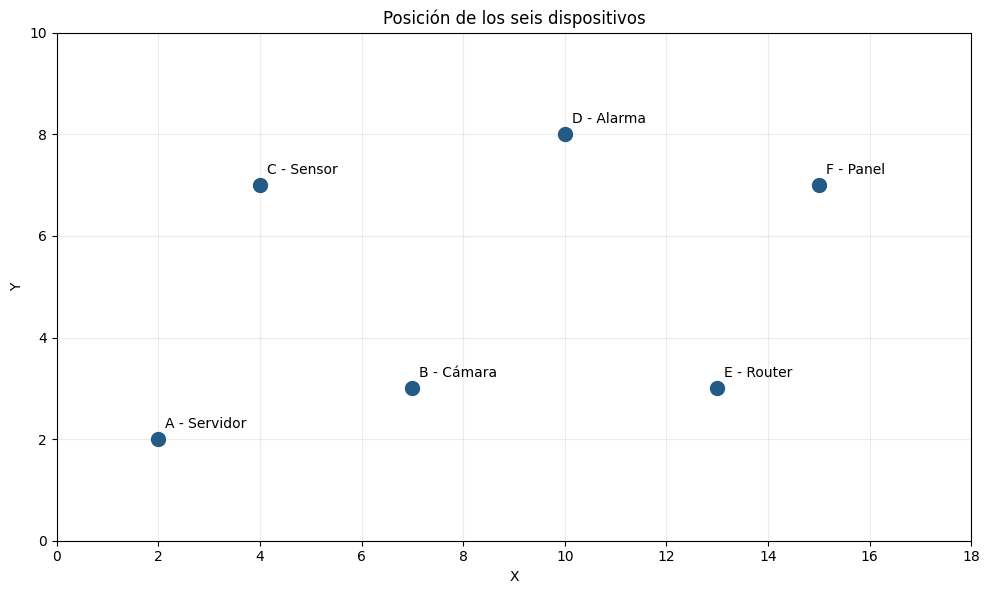

A - B: 5.10
A - C: 5.39
A - D: 10.00
A - E: 11.05
A - F: 13.93
B - C: 5.00
B - D: 5.83
B - E: 6.00
B - F: 8.94
C - D: 6.08
C - E: 9.85
C - F: 11.00
D - E: 5.83
D - F: 5.10
E - F: 4.47


In [5]:
dispositivos = {
    "A": ("Servidor", 2, 2),
    "B": ("Cámara", 7, 3),
    "C": ("Sensor", 4, 7),
    "D": ("Alarma", 10, 8),
    "E": ("Router", 13, 3),
    "F": ("Panel", 15, 7)
}

def graficar_dispositivos(ax):
    for id, (nombre, x, y) in dispositivos.items():
        ax.scatter(x,y,s=100,color="#245b86",zorder=3)
        ax.annotate(f"{id} - {nombre}",(x,y),xytext=(5,8),textcoords="offset points")
    ax.set(xlabel="X",ylabel="Y",xlim=(0,18),ylim=(0,10))
    ax.set_aspect("equal")
    ax.grid(alpha=0.25)

fig, ax = plt.subplots(figsize=(10,6))
graficar_dispositivos(ax)
ax.set_title("Posición de los seis dispositivos")
fig.tight_layout()
plt.show()

aristas = []
ids = list(dispositivos)
for i in range(len(ids)):
    for j in range(i+1,len(ids)):
        a,b = ids[i],ids[j]
        _,x1,y1 = dispositivos[a]
        _,x2,y2 = dispositivos[b]
        distancia = math.sqrt((x2-x1)**2+(y2-y1)**2)
        aristas.append((distancia,a,b))
        print(f"{a} - {b}: {distancia:.2f}")
assert len(aristas) == 15

### Punto 4. Árbol de expansión mínima (Kruskal)
Se ordenan las aristas de menor a mayor peso. Mediante conjuntos disjuntos se verifica si los extremos de una arista pertenecen a componentes diferentes. Si es así, se unen; si no, se descarta para evitar ciclos. Se detiene al seleccionar cinco conexiones. Las distancias se mantienen sin redondear hasta su presentación.

In [6]:
def kruskal(vertices, aristas):
    padre = {v:v for v in vertices}
    rango = {v:0 for v in vertices}

    def encontrar(v):
        if padre[v] != v:
            padre[v] = encontrar(padre[v])
        return padre[v]

    def unir(a,b):
        ra,rb = encontrar(a),encontrar(b)
        if ra == rb:
            return False
        if rango[ra] < rango[rb]:
            padre[ra] = rb
        elif rango[ra] > rango[rb]:
            padre[rb] = ra
        else:
            padre[rb] = ra
            rango[ra] += 1
        return True

    mst = []
    for peso,a,b in sorted(aristas):
        if unir(a,b):
            mst.append((peso,a,b))
            if len(mst) == len(vertices)-1:
                break
    return mst

print("Aristas ordenadas por peso:")
for peso,a,b in sorted(aristas):
    print(f"{a} - {b}: {peso:.2f}")

mst = kruskal(ids, aristas)
total = sum(peso for peso,a,b in mst)
print("\nConexiones seleccionadas:")
for peso,a,b in mst:
    print(f"{a} - {b}: {peso:.2f}")
print(f"Longitud total de cable: {total:.2f}")
assert len(mst) == len(ids)-1

Aristas ordenadas por peso:
E - F: 4.47
B - C: 5.00
A - B: 5.10
D - F: 5.10
A - C: 5.39
B - D: 5.83
D - E: 5.83
B - E: 6.00
C - D: 6.08
B - F: 8.94
C - E: 9.85
A - D: 10.00
C - F: 11.00
A - E: 11.05
A - F: 13.93

Conexiones seleccionadas:
E - F: 4.47
B - C: 5.00
A - B: 5.10
D - F: 5.10
B - D: 5.83
Longitud total de cable: 25.50


### Punto 5. Visualización final
Se dibujan únicamente las conexiones seleccionadas por Kruskal, indicando el peso de cada conexión y la longitud total.

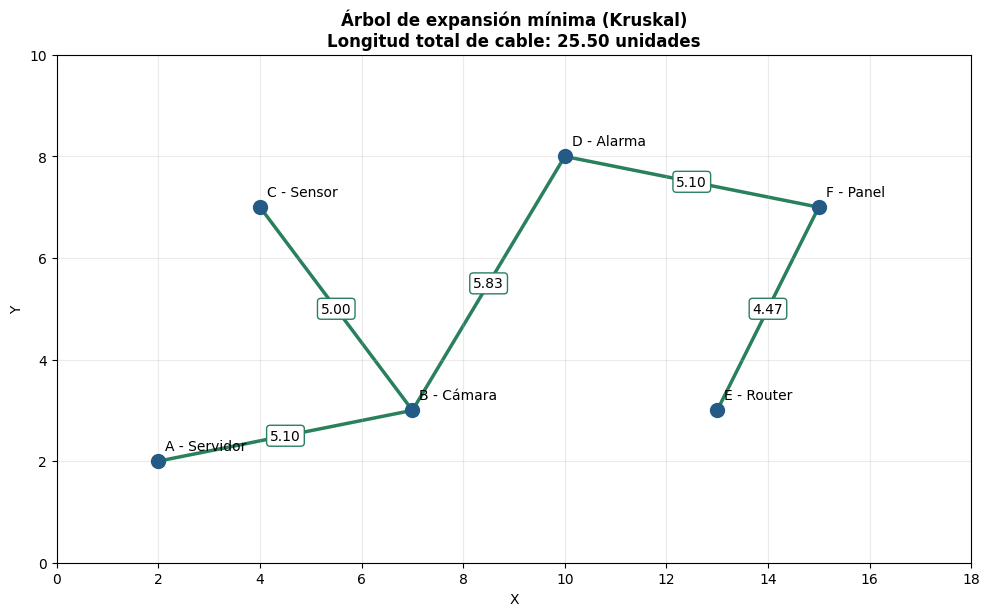

In [7]:
fig, ax = plt.subplots(figsize=(10,6))
for peso,a,b in mst:
    _,x1,y1 = dispositivos[a]
    _,x2,y2 = dispositivos[b]
    ax.plot([x1,x2],[y1,y2],color="#29805c",linewidth=2.5,zorder=1)
    ax.annotate(f"{peso:.2f}",((x1+x2)/2,(y1+y2)/2),ha="center",va="center",bbox=dict(boxstyle="round,pad=0.25",facecolor="white",edgecolor="#29805c"),zorder=4)
graficar_dispositivos(ax)
ax.set_title(f"Árbol de expansión mínima (Kruskal)\nLongitud total de cable: {total:.2f} unidades",weight="bold")
fig.tight_layout()
plt.show()

## 7) Tests aplicados
Se comprueba la propiedad del Max-Heap, el orden de extracción, la inserción, las distancias y la conectividad. Para verificar independientemente el costo mínimo del MST de este caso pequeño, se enumeran las 3003 combinaciones de cinco aristas y se calcula el menor costo entre las que conectan los seis dispositivos. Esta búsqueda exhaustiva se usa solo como prueba, no como algoritmo de producción.

In [8]:
from itertools import combinations

prueba = [
    ("T01", "Configurar servidor", 6),
    ("T02", "Reparar sensor", 10),
    ("T03", "Actualizar software", 4),
    ("T04", "Revisar cámara", 8),
    ("T05", "Generar respaldo", 3),
    ("T06", "Configurar alarma", 7)
]

build_max_heap(prueba)
assert es_max_heap(prueba) and prueba[0][0] == "T02"
assert len(prueba) == 6
print("Test 1: construcción del Max-Heap - OK")

assert extract_max(prueba)[0] == "T02" and es_max_heap(prueba)
print("Test 2: primera extracción - OK")

assert extract_max(prueba)[0] == "T04" and es_max_heap(prueba)
print("Test 3: segunda extracción - OK")

insertar(prueba, ("T07", "Falla en sistema contra incendios", 12))
assert prueba[0][0] == "T07" and es_max_heap(prueba)
assert {t[0] for t in prueba} == {"T01", "T03", "T05", "T06", "T07"}
print("Test 4: inserción y conservación de tareas - OK")

assert len(aristas) == 15
assert len({frozenset((a,b)) for _,a,b in aristas}) == 15
assert all(math.isclose(p, math.hypot(dispositivos[a][1]-dispositivos[b][1], dispositivos[a][2]-dispositivos[b][2])) for p,a,b in aristas)
print("Test 5: distancias euclidianas sin duplicados - OK")

def conectado(vertices, conexiones):
    visitados = {vertices[0]}
    while True:
        cantidad = len(visitados)
        for _,a,b in conexiones:
            if a in visitados or b in visitados:
                visitados.update((a,b))
        if len(visitados) == cantidad:
            return visitados == set(vertices)

assert len(mst) == len(ids)-1 == 5
assert conectado(ids, mst)
print("Test 6: conectividad y ausencia de ciclos - OK")

minimo = min(sum(p for p,a,b in opciones)
             for opciones in combinations(aristas, len(ids)-1)
             if conectado(ids, opciones))
assert math.isclose(total, minimo, rel_tol=1e-12)
assert math.isclose(total, 2*math.sqrt(26)+5+math.sqrt(20)+math.sqrt(34))
print(f"Test 7: costo mínimo comprobado por búsqueda exhaustiva ({minimo:.2f}) - OK")

vacio = []
build_max_heap(vacio)
try:
    extract_max(vacio)
except IndexError:
    pass
else:
    raise AssertionError("Debe detectar una cola vacía")
insertar(vacio, ("X", "Prueba", 1))
assert extract_max(vacio)[0] == "X" and not vacio
print("Test 8: cola vacía y cola de un elemento - OK")

print("\n8 de 8 tests aprobados.")

Test 1: construcción del Max-Heap - OK
Test 2: primera extracción - OK
Test 3: segunda extracción - OK
Test 4: inserción y conservación de tareas - OK
Test 5: distancias euclidianas sin duplicados - OK
Test 6: conectividad y ausencia de ciclos - OK
Test 7: costo mínimo comprobado por búsqueda exhaustiva (25.50) - OK
Test 8: cola vacía y cola de un elemento - OK

8 de 8 tests aprobados.


### Conclusión de las pruebas
La implementación permite procesar las tareas en orden de prioridad y conservar la propiedad del Max-Heap. Kruskal conecta los seis dispositivos con cinco aristas, sin ciclos, y obtiene una longitud mínima de cable de **25,50 unidades**. La búsqueda exhaustiva independiente confirma este resultado para los datos del problema.